# STATE Codex r2 — 02 Baseline cross-cell-line distance

Run All invokes the source pipeline with `--force`: it recalculates the selected investigation from verified public inputs. Existing downloads can be reused after verification; derived result tables are not a substitute for the default calculation. The completed execution runs on exxact05. Use the documented Python environment and allow the source downloads, CPU time and disk space on a cold run.

The notebooks distinguish measured outcomes from investigations that originally stopped before scoring. For those stops, the reproduced objects are input levels, eligibility, resource diagnostics and the recorded decision; no performance curve is invented. Original results are comparison targets and historical evidence only. Reconstructed choices and numerical differences remain explicit.

See the [original report](../originals/REPORT.md), [candidate ledger](../originals/supporting/audit/candidate_axis_ledger.csv), [public sources](../methods/sources.json) and [pipeline](../methods/run_pipeline.py).

## 1. Data acquisition

The prospective feature uses DepMap24Q4 baseline expression and an independent HPA cell-line atlas. Official Replogle ST-SE/ST-HVG releases provide original predicted/observed DE rows; original observation metadata provide treated/control counts. Source versions and hashes are explicit in the manifest.

In [1]:
from pathlib import Path
import importlib.util,json,sys
import numpy as np
import pandas as pd
from IPython.display import display,JSON,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'methods/replogle.py').is_file() and (p/'originals/REPORT.md').is_file())
spec=importlib.util.spec_from_file_location('state_codex_r2_notebook',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
pd.set_option('display.max_colwidth',100);pd.set_option('display.max_rows',100)
manifest=wf.read_json(ROOT,'methods/sources.json')
sources=pd.DataFrame(manifest['inputs'])
display(sources[['path','bytes','sha256','url']])
if manifest.get('remote_observations'):
    display(Markdown('**Pinned observation-only source objects used for Replogle cell counts**'))
    display(pd.DataFrame(manifest['remote_observations']))
wf.source_functions(ROOT,'methods/acquire.py',['main'])
print('Manifest public input records:',len(sources))
print('The next cell executes actual source calculation for this investigation.')


,path,bytes,sha256,url
0,metadata/generalization.toml,150875,eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783,https://raw.githubusercontent.com/ArcInstitute/state/da4178c930dc917dac6b56faf10a33e21bd8e905/st...
1,metadata/depmap_24q4_protein_coding_tpm_logp1.csv,506628654,2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56,https://ndownloader.figshare.com/files/51065489
2,metadata/depmap_24q4_model.csv,645696,b7a0c1385e6cef30132b56aff61f1261d11e3f490490b355c430d32ee0dbdcfa,https://ndownloader.figshare.com/files/51065297
3,metadata/hpa_rna_celline.tsv.zip,205861141,e5b11779308c2720cfe89d9cb19932ad4c0c3fea0fa37e8c61a14d501995852a,https://www.proteinatlas.org/download/tsv/rna_celline.tsv.zip
4,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv,344243692,230ac1f1f8342d0c7f563166b6e8f9afeae6a02a62d0b737fda64168dde49ba0,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
5,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv,343530568,a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
6,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,528013,eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
7,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv,380905134,fd3422f18087eaf8357112bc0fd87faa8f95ed2a9ad95f0e7c4107d52754a9ca,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
8,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv,380988038,68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,568100,372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


**Pinned observation-only source objects used for Replogle cell counts**

,path,url,bytes,sha256,evidence
0,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3079506036,6951f4bffb532950c447e8dc300b2f42ab381c854273327f8cd38b84cfa4eb42,Pinned original release; observation-only range extraction
1,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3012265108,9df1a21e3b159fa3900a32dd8bd6b4d6dd8750838014d1d3997932d7cedc9673,Pinned original release; observation-only range extraction
2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,1577727376,75f79feff37c4334559ea88c1e2a27acd306eb7dee5a2e25f37c4860014ca2b9,Pinned original release; observation-only range extraction
3,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,2837025870,f3363768db24b7eee9cb55507443366f8e15b6f9e5731ac415f533b757a5b5b1,Pinned original release; observation-only range extraction


**Executed implementation:** `methods/acquire.py::main`

def main():
    ap=argparse.ArgumentParser();ap.add_argument('--root',type=Path,required=True);ap.add_argument('--reuse',type=Path);ap.add_argument('--manifest-only',action='store_true');ap.add_argument('--refresh-manifest',action='store_true');a=ap.parse_args();r=a.root.resolve()
    p=r/'methods/sources.json';m=json.loads(p.read_text()) if p.exists() and not a.refresh_manifest else manifest(r)
    if a.manifest_only:return
    reuse={}
    if a.reuse:
        for x in json.loads((a.reuse/'methods/sources.json').read_text())['inputs']:reuse[x['sha256']]=a.reuse/'inputs'/x['path']
    def one(x):
        p=r/'inputs'/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
        if p.exists() and p.stat().st_size==x['bytes'] and sha(p)==x['sha256']:return {**x,'verified':True,'route':'existing'}
        q=reuse.get(x['sha256'])
        if q and q.exists() and q.stat().st_size==x['bytes'] and sha(q)==x['sha256']:
            p.symlink_to(q.resolve());print('REUSE',x['path'],flush=True);return {**x,'verified':True,'route':'identical_sha256_symlink'}
        tmp=p.with_name(p.name+'.part')
        for attempt in range(4):
            try:
                with urllib.request.urlopen(x['url'],timeout=180) as src,tmp.open('wb') as dst:
                    for b in iter(lambda:src.read(8*1024*1024),b''):dst.write(b)
                assert tmp.stat().st_size==x['bytes'],(tmp.stat().st_size,x['bytes'])
                assert sha(tmp)==x['sha256'],'Source checksum mismatch'
                os.replace(tmp,p);print('VERIFIED',x['path'],x['bytes'],flush=True)
                return {**x,'verified':True,'route':'public_download'}
            except Exception:
                if attempt==3:raise
                time.sleep(2*(attempt+1))
    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:done=list(pool.map(one,m['inputs']))
    (r/'inputs/DOWNLOAD_RECEIPT.json').write_text(json.dumps(dict(source_manifest_sha256=sha(r/'methods/sources.json'),inputs=done),indent=2)+'\n')

Manifest public input records: 49
The next cell executes actual source calculation for this investigation.


## 2. Processing

Rebuild reference gene intersections and context mappings, compute baseline distances, score real prediction/observation vectors, and derive observation counts. The frozen contract defines mean1−Spearman distance to the other three contexts. The report calls this cosine distance; the implementation follows the specific frozen definition and retains that discrepancy visibly.

In [2]:
pipeline=wf.run_pipeline(ROOT,'distance')
wf.source_functions(ROOT,'methods/replogle.py',['axes','de_matrix','row_spearman'])
axis=wf.read_csv(ROOT,'computed/replogle/axis.csv')
display(axis);display(JSON(wf.read_json(ROOT,'computed/replogle/axis_summary.json')))
wf.source_receipts(ROOT,['replogle_axis','replogle_scores','replogle_observations','replogle_analysis'])


Calculating the original source workflow for distance ; source files are verified before reuse.


Calculating from source inputs: replogle_axis


Calculating from source inputs: replogle_scores


REPL DE ST-SE-Replogle k562 real


REPL DE ST-SE-Replogle k562 pred


REPL DE ST-SE-Replogle jurkat real


... (32 outputs left out)

**Calculated stage:** replogle_observations

<IPython.core.display.JSON object>

**Calculated stage:** replogle_analysis

<IPython.core.display.JSON object>

## 3. Axis

The original nearest-context form A1a generated only two distinct symmetric distances and was rejected before outcomes. A1b averages distances to the three training contexts and produces four levels. HPA primary and JurkatE6.1 sensitivity values are independent input-side checks. The report’s “gene-block sensitivity” wording conflicts with the retained specific JurkatE6.1 record; no gene-block scheme is invented.

In [3]:
display(axis[['context','nearest_distance','distance','hpa_distance','hpa_e61_distance']])
print('Calculated nearest distinct values:',axis.nearest_distance.round(12).nunique())
print('Calculated panel-mean distinct values:',axis.distance.round(12).nunique())
display(JSON(wf.read_json(ROOT,'originals/supporting/audit/axis/frozen_axis.json')))
wf.original_rows(ROOT,['A1a'])


,context,nearest_distance,distance,hpa_distance,hpa_e61_distance
0,k562,0.151676,0.180460,0.185824,0.187261
1,jurkat,0.151676,0.183549,0.192026,0.203245
2,hepg2,0.191412,0.194748,0.198047,0.200703
3,rpe1,0.191412,0.195752,0.211327,0.218453


Calculated nearest distinct values: 2
Calculated panel-mean distinct values: 4


<IPython.core.display.JSON object>

,candidate_id,axis,status,decision_reason,next_action
0,A1a,nearest-training-context held-out cell-line transcriptomic distance,negative,prospective validation produced only two unique symmetric pair distances and cannot form a nontr...,replaced before target access by panel-mean aggregation


These are attributed original decisions, not new adjudications.


,candidate_id,axis,hypothesis_source,prospective_feature,mechanism,required_controls,status,decision_reason,next_action
0,A1a,nearest-training-context held-out cell-line transcriptomic distance,user-prioritized predeclared,minimum unperturbed expression distance,cell-state extrapolation should weaken transfer,effect magnitude; DE genes; cell count; modality; dose/time; checkpoint family; representation; ...,negative,prospective validation produced only two unique symmetric pair distances and cannot form a nontr...,replaced before target access by panel-mean aggregation


## 4. Levels and eligibility

The four measured contexts are sorted by the rebuilt primary distance. The balanced perturbation panel and finite-vector criteria are derived from original per-feature rows, not from the historical638 count. Representation/reference comparisons use the same retained units.

In [4]:
display(axis.sort_values('level'))
display(JSON(wf.read_json(ROOT,'computed/replogle/score_summary.json')))
units=wf.read_csv(ROOT,'computed/replogle/distance_units.csv')
display(units.groupby('context').agg(units=('perturbation','size'),perturbations=('perturbation','nunique')))


,context,distance,nearest_distance,hpa_distance,hpa_e61_distance,level
0,k562,0.180460,0.151676,0.185824,0.187261,1
1,jurkat,0.183549,0.151676,0.192026,0.203245,2
2,hepg2,0.194748,0.191412,0.198047,0.200703,3
3,rpe1,0.195752,0.191412,0.211327,0.218453,4


<IPython.core.display.JSON object>

,units,perturbations
context,,
hepg2,638,638
jurkat,638,638
k562,638,638
rpe1,638,638


## 5. Model / released scores

Recalculate signed Spearman between predicted and observed log2 fold changes. The fixed reference averages the same perturbation’s real effects in the other three contexts and never predicts from the held-out outcome. Actual error-independent effect/count controls are shown with each unit.

In [5]:
wf.source_functions(ROOT,'methods/replogle.py',['scores'])
wf.source_functions(ROOT,'methods/observation_controls.py',['run'])
display(units[['context','perturbation','distance','state_se','state_hvg','reference','effect_rms','n_de','n_treated','n_control']].head(12))


**Executed implementation:** `methods/replogle.py::scores`

def scores(root):
    out=root/'computed/replogle';out.mkdir(parents=True,exist_ok=True);sources=[];mats={};sig={};availability=[]
    for model in ['ST-SE-Replogle','ST-HVG-Replogle']:
        for c in CTX:
            for kind in ['real','pred']:
                p=checked(root,f'{model}/zeroshot/{c}/eval_best.ckpt/{c}_{kind}_de.csv');sources.append(p);print('REPL DE',model,c,kind,flush=True)
                mat,n=de_matrix(p);mats[model,c,kind]=mat;sig[model,c,kind]=n
                availability.extend(dict(model=model,context=c,kind=kind,perturbation=g) for g in mat.index)
    # Official primary source eligibility; representation intersection is an
    # explicit secondary join and cannot change discovery identities silently.
    primary_sets=[set(mats['ST-SE-Replogle',c,k].index) for c in CTX for k in ['real','pred']]
    balanced=set.intersection(*primary_sets);union=set.union(*primary_sets);remaining=union-balanced
    elig=[]
    for p in sorted(union):
        row=dict(perturbation=p,discovery=p in balanced,confirmation_candidate=p in remaining)
        for c in CTX:
            row[c+'_real']=p in mats['ST-SE-Replogle',c,'real'].index;row[c+'_pred']=p in mats['ST-SE-Replogle',c,'pred'].index
        row['confirmation_eligible']=p in remaining and all(row[c+'_'+k] for c in CTX for k in ['real','pred']);elig.append(row)
    pd.DataFrame(elig).to_csv(out/'A2_eligibility.csv',index=False);pd.DataFrame(availability).to_csv(out/'released_condition_availability.csv',index=False)
    genes=sorted(set.intersection(*(set(m.columns) for m in mats.values())),key=str);perts=sorted(balanced);real={c:mats['ST-SE-Replogle',c,'real'].reindex(index=perts,columns=genes).values for c in CTX}
    rows=[]
    for c in CTX:
        truth=real[c];other=[real[x] for x in CTX if x!=c];ref=np.mean(other,axis=0);rms=np.sqrt(np.nanmean(truth**2,axis=1));expected=np.mean([np.sqrt(np.nanmean(x**2,axis=1)) for x in other],axis=0)
        se=row_spearman(truth,mats['ST-SE-Replogle',c,'pred'].reindex(index=perts,columns=genes).values)
        hv=row_spearman(truth,mats['ST-HVG-Replogle',c,'pred'].reindex(index=perts,columns=genes).values);rr=row_spearman(truth,ref)
        for j,p in enumerate(perts):rows.append(dict(context=c,perturbation=p,state_se=se[j],state_hvg=hv[j],reference=rr[j],effect_rms=rms[j],expected_rms=expected[j],n_de=int(sig['ST-SE-Replogle',c,'real'][p]),features=int(np.isfinite(truth[j]).sum())))
    d=pd.DataFrame(rows);valid=d.groupby('perturbation').apply(lambda x:len(x)==4 and np.isfinite(x[['state_se','state_hvg','reference']].values).all(),include_groups=False);d=d[d.perturbation.isin(valid[valid].index)].copy()
    d.to_csv(out/'unit_scores.csv',index=False)
    summary=dict(primary_balanced_perturbations=len(balanced),finite_balanced_perturbations=d.perturbation.nunique(),common_output_features=len(genes),disjoint_candidates=len(remaining),eligible_disjoint_candidates=sum(x['confirmation_eligible'] for x in elig))
    dump(out/'score_summary.json',summary);save_receipt(root,'replogle_scores',sources,[out/'unit_scores.csv',out/'A2_eligibility.csv',out/'released_condition_availability.csv',out/'score_summary.json'],summary,['Nonpositive fold_change is excluded before log2; no pseudocount is invented.','Duplicate output-feature entries collapse by mean log2 fold change.'])
    return d

**Executed implementation:** `methods/observation_controls.py::run`

def run(root):
    out=root/'computed/replogle';out.mkdir(parents=True,exist_ok=True);inp=root/'inputs/observation_extracts';inp.mkdir(parents=True,exist_ok=True)
    spec=json.loads((root/'methods/sources.json').read_text())['remote_observations'];parts=[];evidence=[]
    fs=fsspec.filesystem('http')
    for x in spec:
        context=x['path'].split('/')[2];print('OBSERVATIONS',context,flush=True)
        with fs.open(x['url'],'rb',block_size=262144,cache_type='blockcache',size=x['bytes']) as f:
            with h5py.File(f,'r') as h:
                d=pd.DataFrame({k:field(h['obs'],k) for k in ['gene','cell_line','gem_group','pert_cell_barcode','ctrl_cell_barcode']})
        if d.cell_line.nunique()!=1:raise ValueError('Unexpected context mixing')
        p=inp/f'{context}.parquet';d.to_parquet(p,index=False)
        counts=d.groupby('gene',observed=True).agg(n_treated=('pert_cell_barcode','nunique'),n_control=('ctrl_cell_barcode','nunique'),n_rows=('gene','size')).reset_index().rename(columns={'gene':'perturbation'})
        counts['context']=context;parts.append(counts)
        evidence.append(dict(source=x,access='Pinned immutable H5AD; HTTP range extraction of obs only',full_source_sha256_verified=False,extracted_path=str(p.relative_to(root)),extracted_sha256=sha(p),extracted_rows=len(d)))
    result=pd.concat(parts,ignore_index=True);result.to_csv(out/'cell_counts.csv',index=False);dump(out/'observation_source_receipt.json',evidence)
    save_receipt(root,'replogle_observations',[inp/f'{x["path"].split("/")[2]}.parquet' for x in spec],[out/'cell_counts.csv',out/'observation_source_receipt.json'],dict(contexts=len(parts),unique_condition_rows=len(result),count_definition='nunique pert_cell_barcode and nunique ctrl_cell_barcode within original gene/context'),['Raw H5AD arrays are not downloaded; input-side observation extraction is pinned to original release objects and retains extracted-table checksums.'])

,context,perturbation,distance,state_se,state_hvg,reference,effect_rms,n_de,n_treated,n_control
0,k562,AAAS,0.18046,-0.002881,0.023888,-0.041077,0.179836,9,202,199
1,k562,AARS,0.18046,0.304736,0.341317,0.367937,0.694914,260,38,38
2,k562,ABCB7,0.18046,0.150422,0.156359,0.225862,0.212345,81,192,189
3,k562,ABHD11,0.18046,-0.021957,0.021292,0.025904,0.413468,13,49,49
4,k562,ACTR1B,0.18046,0.020242,-0.033335,0.011623,0.175968,4,200,197
5,k562,ACTR2,0.18046,-0.018176,-0.019372,0.033962,0.172604,20,221,219
6,k562,ACTR6,0.18046,-0.002145,0.060107,0.307958,0.370001,108,104,103
7,k562,ACTR8,0.18046,0.021507,0.041095,0.280554,0.255776,223,242,239
8,k562,AIFM1,0.18046,0.043115,-0.001187,0.037112,0.437968,13,40,40
9,k562,ALDOA,0.18046,0.150969,0.173971,0.302067,0.426611,191,77,77


## 6. Curves, controls and diagnostics

Recompute raw/adjusted perturbation-block fits, the ST-HVG representation check, matched reference, context curves and all24 exact context permutations. Numerical reconstruction differences, including the small independent-atlas value differences, remain visible rather than being selected away.

**Executed implementation:** `methods/common.py::fisher`

def fisher(x):return np.arctanh(np.clip(np.asarray(x,float),-1+1e-7,1-1e-7))

**Executed implementation:** `methods/common.py::cluster_fit`

def cluster_fit(d,y,x,cluster,adjust=(),fixed=(),cluster_fixed=False,draws=10000,seed=20260715):
    """OLS and paired cluster-resampling percentile CI via exact sufficient stats.

    When cluster_fixed=True, first remove the cluster mean. Resampling duplicated
    clusters is equivalent to giving that cluster an integer frequency weight.
    Axis standardization is fixed on the original analyzed rows, not redefined
    within each bootstrap draw. No historical estimates enter this function.
    """
    cols=[y,x,cluster,*adjust,*fixed];d=d.dropna(subset=cols).copy()
    X=[np.ones(len(d)),zscore(d[x])];names=['intercept',x]
    for c in adjust:
        v=np.asarray(d[c],float)
        if np.std(v)>0:X.append(zscore(v));names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:X.append((d[c]==val).astype(float).values);names.append(f'{c}={val}')
    X=np.column_stack(X);Y=d[y].to_numpy(float)
    groups=sorted(d[cluster].unique());codes=pd.Categorical(d[cluster],categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel=codes==j;X[sel]-=X[sel].mean(axis=0);Y[sel]-=Y[sel].mean()
        X=X[:,1:];names=names[1:];axis_idx=0
    else:axis_idx=1
    gxx=np.zeros((len(groups),X.shape[1],X.shape[1]));gxy=np.zeros((len(groups),X.shape[1]))
    for j in range(len(groups)):
        sel=codes==j;gxx[j]=X[sel].T@X[sel];gxy[j]=X[sel].T@Y[sel]
    coefficient=np.linalg.lstsq(X,Y,rcond=None)[0];rng=np.random.default_rng(seed);boot=[]
    for start in range(0,draws,100):
        n=min(100,draws-start);w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=n)
        xx=np.einsum('bg,gij->bij',w,gxx);xy=w@gxy
        for a,b in zip(xx,xy):boot.append(np.linalg.lstsq(a,b,rcond=None)[0][axis_idx])
    return dict(n=len(d),clusters=len(groups),coefficient=float(coefficient[axis_idx]),ci95=np.quantile(boot,[.025,.975]).tolist(),draws=draws,seed=seed,design_columns=names,cluster_fixed_effect=cluster_fixed,axis_standardization='population SD on all analyzed rows',coefficients=dict(zip(names,coefficient))),np.asarray(boot)

**Executed implementation:** `methods/common.py::curve`

def curve(d,level,score,cluster,draws=10000,seed=20260715):
    groups=sorted(d[cluster].unique());levels=sorted(d[level].unique());rng=np.random.default_rng(seed)
    w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=draws);rows=[];boot={}
    for v in levels:
        q=d[d[level]==v];g=q.groupby(cluster)[score].agg(['sum','count']).reindex(groups,fill_value=0)
        b=(w@g['sum'].values)/(w@g['count'].values);boot[str(v)]=b
        rows.append(dict(level=v,n=len(q),clusters=q[cluster].nunique(),mean=q[score].mean(),ci_low=np.quantile(b,.025),ci_high=np.quantile(b,.975)))
    return pd.DataFrame(rows),boot

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization
0,state_se,2552,638,0.003635,"[0.0003536610607250985, 0.006869264506085516]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows
1,state_hvg,2552,638,0.020938,"[0.016757678311506933, 0.025207889054321433]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows
2,reference,2552,638,0.037459,"[0.03273677017100967, 0.042334413502061616]",10000,20260715,"[intercept, distance]",False,population SD on all analyzed rows
3,adjusted_state_se,2552,638,0.006983,"[0.003020388152357576, 0.010960595420531842]",10000,20260715,"[distance, log_effect_rms, log_n_de, log_n_treated, log_n_control]",True,population SD on all analyzed rows
4,adjusted_state_se_pooled_sensitivity,2552,638,-0.030512,"[-0.03499153355030928, -0.025969557834368856]",10000,20260715,"[intercept, distance, log_effect_rms, log_n_de, log_n_treated, log_n_control]",False,population SD on all analyzed rows


<IPython.core.display.JSON object>

,level,n,clusters,mean,ci_low,ci_high,metric
0,1,638,638,0.100638,0.090156,0.111543,state_se
1,2,638,638,0.102253,0.091862,0.112740,state_se
2,3,638,638,0.148749,0.135377,0.162106,state_se
3,4,638,638,0.073206,0.063872,0.082273,state_se
4,1,638,638,0.126389,0.114338,0.138696,state_hvg
5,2,638,638,0.175628,0.161868,0.189698,state_hvg
6,3,638,638,0.150354,0.137739,0.163228,state_hvg
7,4,638,638,0.211823,0.195448,0.228625,state_hvg
8,1,638,638,0.174592,0.161761,0.187711,reference
9,2,638,638,0.194659,0.181399,0.208239,reference


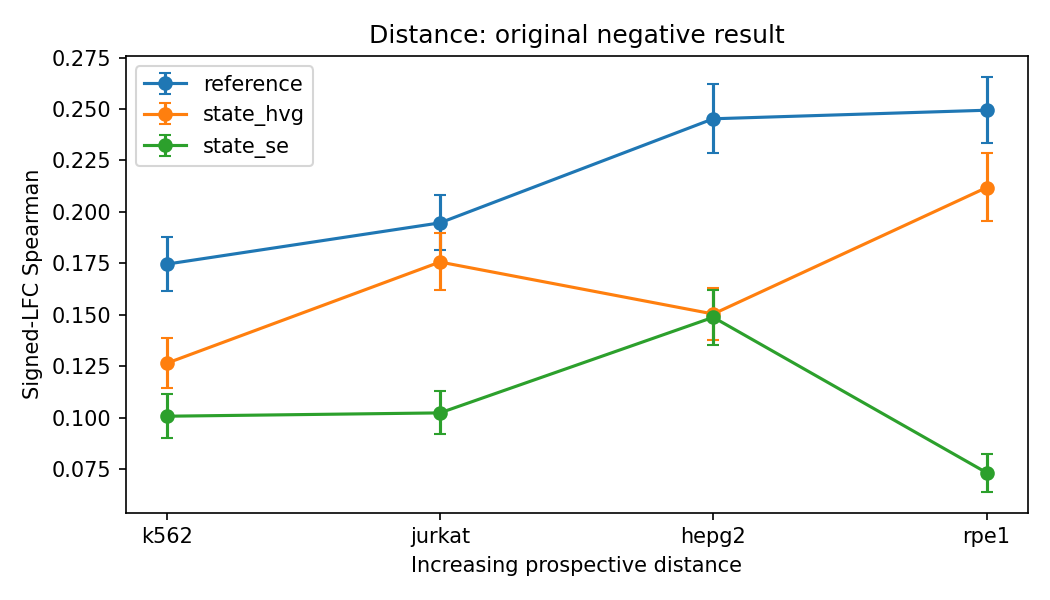

,metric,historical,reconstructed,difference
0,state_se,0.003635,0.003635,-4.143054e-10
1,state_hvg,0.020938,0.020938,-5.551115e-17
2,reference,0.037459,0.037459,8.625055e-11
3,adjusted_state_se,0.006983,0.006983,-4.673278e-10
4,adjusted_state_se_pooled_sensitivity,0.006983,-0.030512,-3.749525e-02


Original recorded numbers are comparison targets; differences do not select the calculation method.


In [6]:
wf.source_functions(ROOT,'methods/common.py',['fisher','cluster_fit','curve'])
result=wf.read_json(ROOT,'computed/replogle/distance_summary.json')
wf.show_fits(result);display(JSON(result['exact_context_permutation']))
display(wf.read_csv(ROOT,'computed/replogle/distance_curve.csv'))
wf.show_curve(ROOT,'distance_curve.png')
wf.compare(ROOT,'computed/replogle/historical_comparison.json')


## 7. Historical result and decision

The original agent rejected A1b because the full ordered curve did not support the predicted deterioration, despite a localized endpoint difference. The original disposition and exact recorded grounds remain distinct from the recalculated coefficients and curve above.

In [7]:
wf.original_rows(ROOT,['A1a','A1b'])
print('The isolated RPE1 endpoint was not the original distance-axis finding; the whole frozen ordering was evaluated.')


,candidate_id,axis,status,decision_reason,next_action
0,A1a,nearest-training-context held-out cell-line transcriptomic distance,negative,prospective validation produced only two unique symmetric pair distances and cannot form a nontr...,replaced before target access by panel-mean aggregation
1,A1b,panel-mean held-out cell-line transcriptomic distance,negative,"powered n=638; primary SE slope +0.00364 CI [0.00052,0.00687], HVG slope +0.02094; adjusted +0.0...",continue prospective discovery; do not call localized RPE1 endpoint a distance SPC


These are attributed original decisions, not new adjudications.
The isolated RPE1 endpoint was not the original distance-axis finding; the whole frozen ordering was evaluated.
